# Figure 5 - A fixed region of FS-peptide encodes poor local sampling

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** The same FS-peptide as Figure 4, but in these simulations the backbone and side-chain dihedrals of residues 3-10 were frozen (a CAMPARI freeze file), so each replicate is stuck in whatever conformation those residues started in. The blue band marks the frozen residues.

**What to look for.** Inside the frozen region the comparison to the EV limit (B) is close to 1 - each replicate has a single sharp (φ, ψ) value, nothing like the broad EV distribution - so by that measure alone the region looks catastrophically under-sampled. But every replicate was frozen in the *same* conformation, so the all-to-all comparison (C) is essentially 0 there: the replicates agree perfectly. That combination (B ≈ 1, C ≈ 0) is what a reproducibly folded region looks like to PENGUIN - the paper calls this a facsimile of a folded domain - and it is the opposite of the energetic-trap signature seen in Figure 6 (B high *and* C high, because each replicate is stuck somewhere different). Outside the frozen region the residues behave as in Figure 4, and the fractional helicity (E) is negligible throughout, so nothing about the frozen region is helical. This is the synthetic control that anchors the interpretation of every later system: PENGUIN flags the region as unsampled while also telling you the lack of sampling is consistent across replicates.

**Data.** 10 FH replicates with residues 3-10 fixed (3000 frames each), compared against the 10 coil-start EV replicates of the FS-peptide (3000 frames each). `SamplingQuality` pairs trajectories and references one-to-one, so the number of EV replicates must match; the paper's notebook passed all 20 EV runs and earlier SOURSOP versions silently used only the first 10.

**Caption note.** The published caption describes panels B-C as φ-only distances; the figure file in the paper's repository (and the code that produced it) uses the joint 2D φ/ψ distribution, which is what is reproduced here.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Load the simulations

In [2]:
fs_fixed = load_system("fs_peptide_fixed/full", "fs_peptide/ev/coil_start", num_replicates=10,
                       method="2D angle distributions")
sequence = print_sequence(fs_fixed)

10 FH replicates, 10 EV replicates


AAAAAAAARAAAARAAAARAA
.........1.........2.


## How to read a PENGUIN figure

Every PENGUIN summary has the same four panels (the sequence cartoon shown as panel **A** in the paper was drawn in a vector graphics editor, so here we print the sequence with a ruler instead):

* **B - Comparison to the excluded-volume limit.** For every residue and every full-Hamiltonian (FH) replicate, the joint (φ, ψ) distribution is histogrammed and compared to the same residue in the excluded-volume (EV) reference ensemble using the Hellinger distance (0 = identical, 1 = no overlap). Red points are individual replicates; the black line is the replicate mean. Low values mean the residue explores its backbone conformational space about as freely as a chain with no attractive interactions; high values mean the FH ensemble is restricted relative to that limit - which can be genuine structure *or* an energetic trap.
* **C - All-to-all trajectory comparison.** The same Hellinger distance, but between every pair of FH replicates. If independent replicates agree with one another (low values) the restriction seen in **B** is reproducible and therefore reflects the Hamiltonian; if they disagree (high values) each replicate is stuck somewhere different - the signature of poor sampling.
* **D - Spread of B.** The maximum minus minimum Hellinger distance across replicates, per residue; a compact summary of how consistently a residue is scored against the EV limit.
* **E - Fractional helicity.** Per-residue DSSP helicity of the FH replicates, so that any restriction in **B** can be checked against a concrete structural explanation.

The logic of the method is that **B** on its own cannot distinguish folding from trapping, but **B** together with **C** can: reproducible structure gives high **B** / low **C**, whereas energetic traps give high **B** / high **C**.

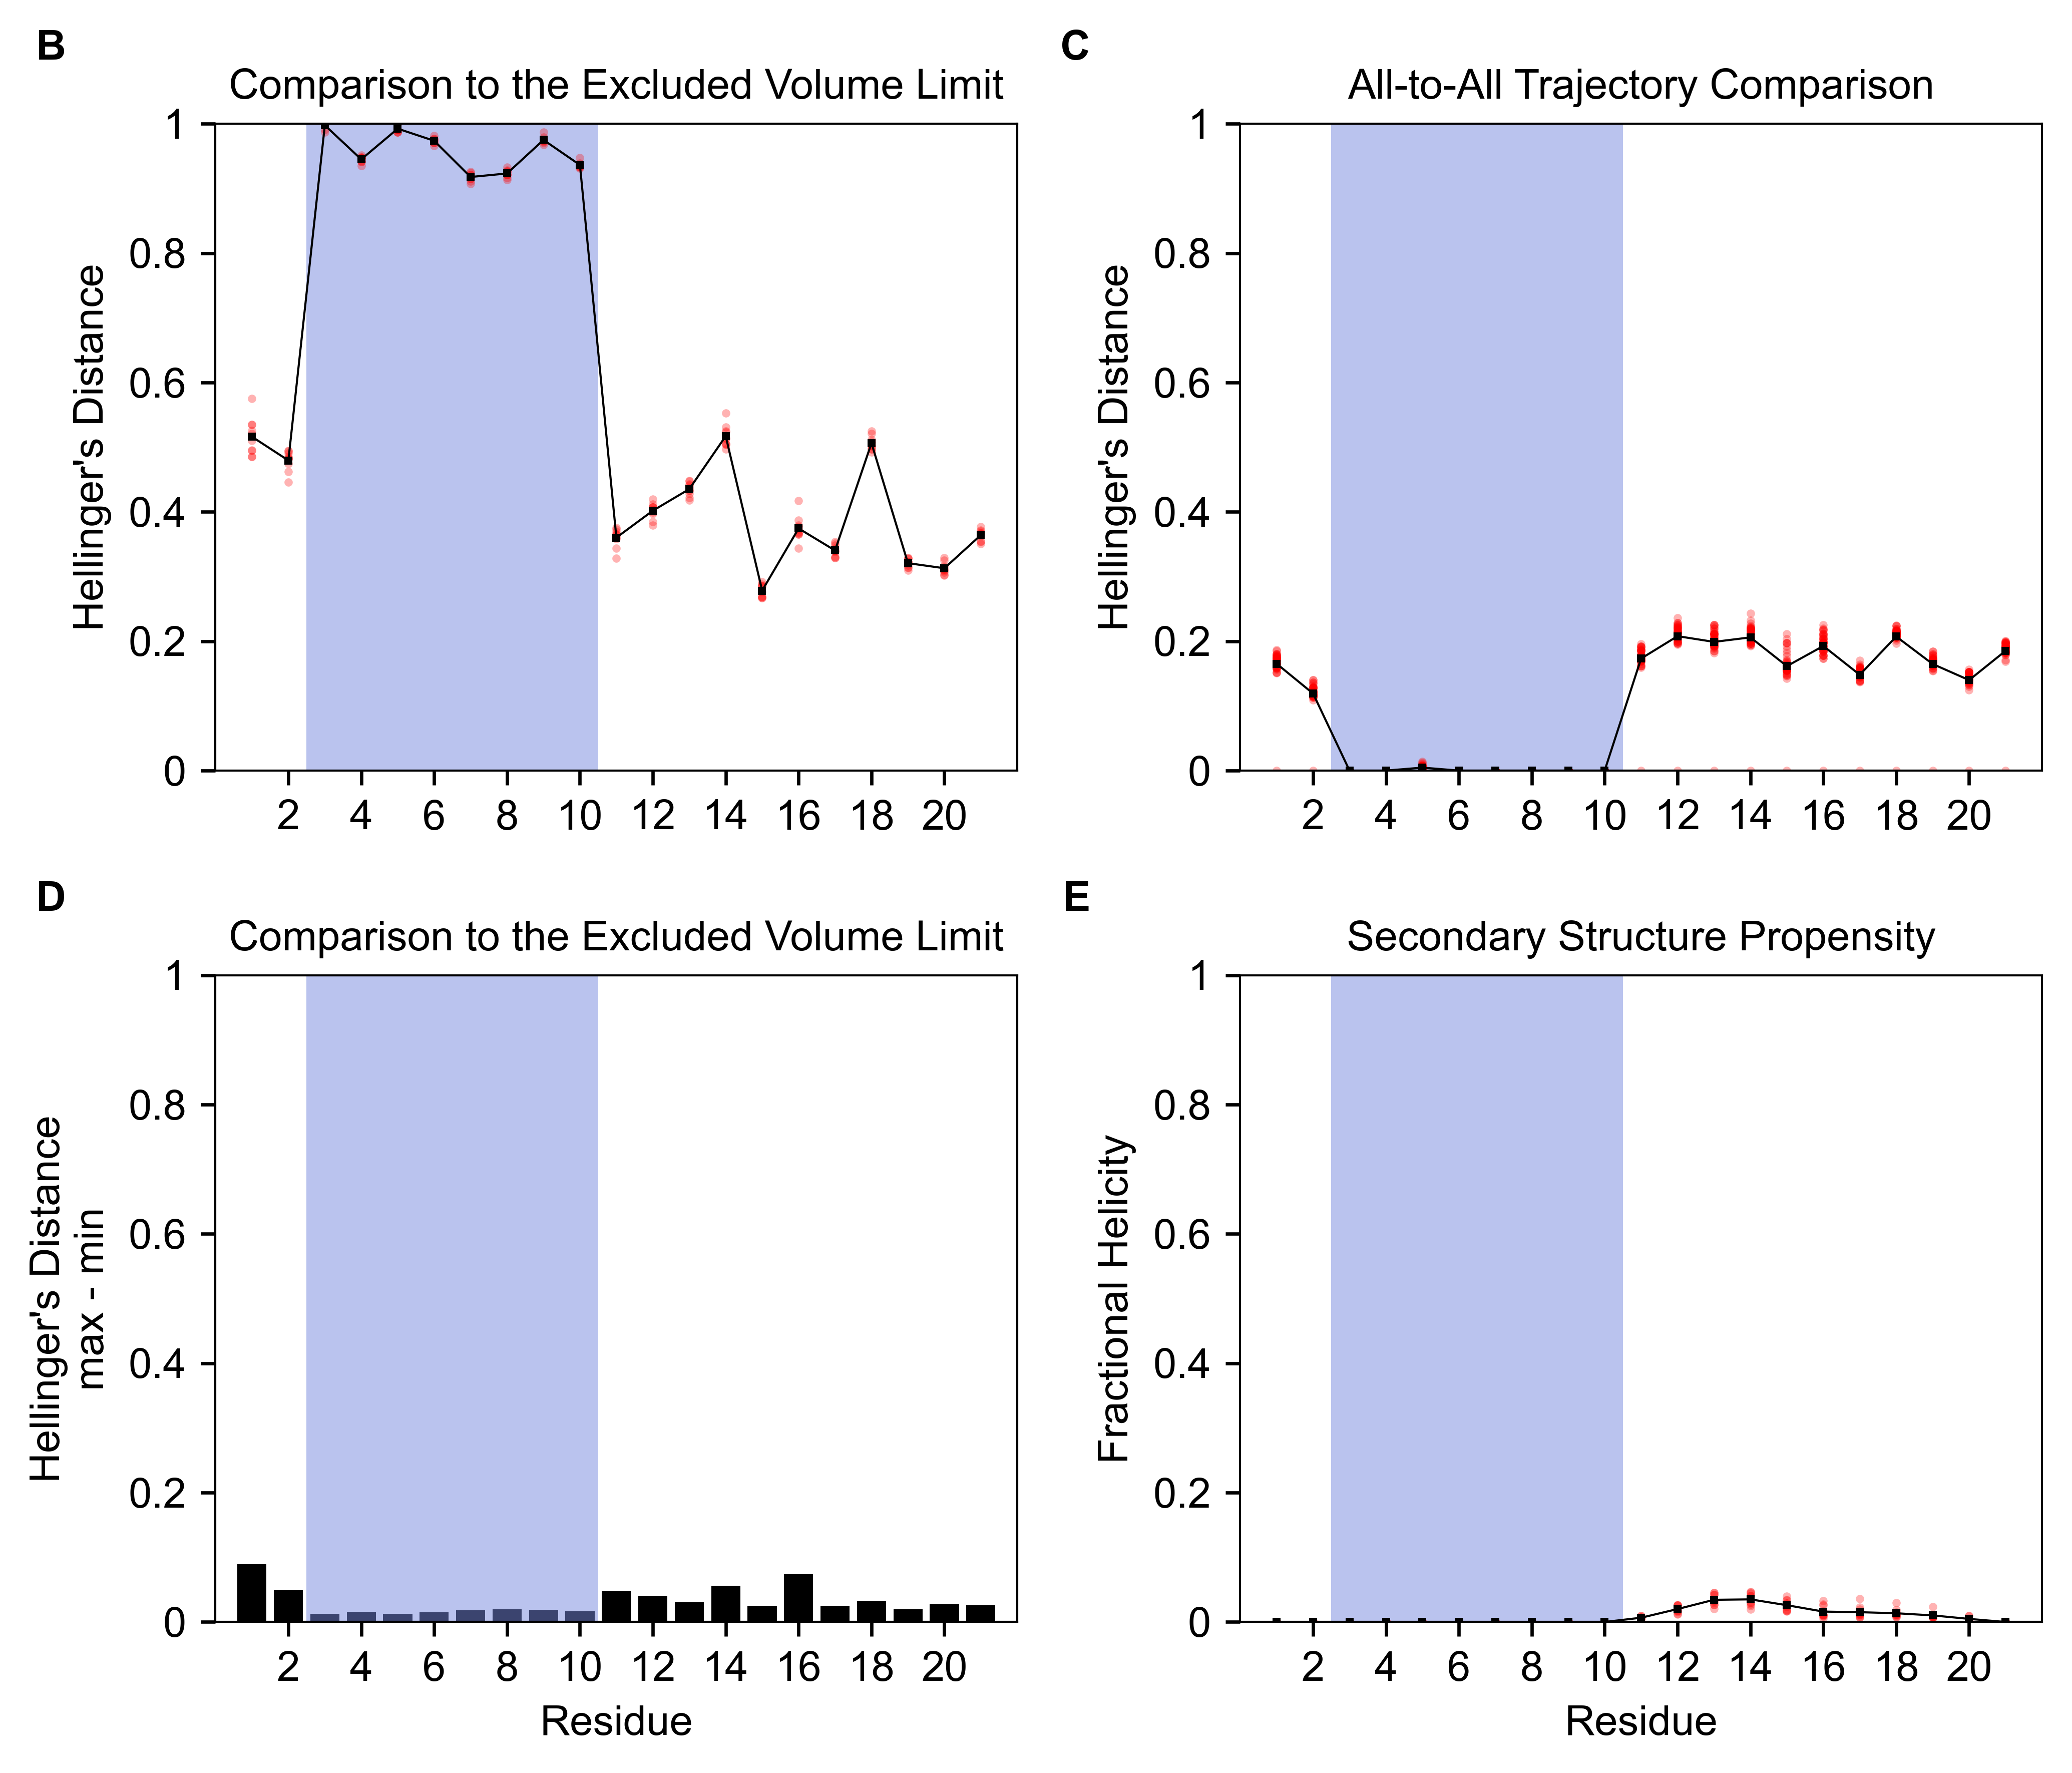

In [3]:
# residues 3-10 were frozen; shade [2.5, 10.5] so the band spans whole residues
fig, axd = penguin_figure(fs_fixed, dihedral="2D", increment=2, figsize=(7, 6), fontsize=10,
                          highlight=(2.5, 10.5), color="#7689de",
                          save_path=figure_path("fig5", "fs_fixed_2D_hellingers.pdf"))

## Frozen versus free residues, in numbers

In [4]:
H = np.asarray(fs_fixed.hellingers_distances())
A = np.asarray(fs_fixed.get_all_to_all_2d_trj_comparison())
frozen = np.arange(2, 10)   # 0-based columns for residues 3-10
free = np.setdiff1d(np.arange(H.shape[1]), frozen)
print(f"mean EV-comparison   frozen {H[:, frozen].mean():.2f}   free {H[:, free].mean():.2f}")
print(f"mean all-to-all      frozen {A[:, frozen].mean():.2f}   free {A[:, free].mean():.2f}")

mean EV-comparison   frozen 0.96   free 0.40
mean all-to-all      frozen 0.00   free 0.17
